In [1]:
pip install pandas torch transformers openpyxl scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 40.8 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [2]:
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.preprocessing import LabelEncoder
import numpy as np
from tqdm import tqdm
from google.colab import drive
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Data Preparation ========================================================
drive.mount('/content/drive')

# Load labeled data
df_labeled = pd.read_excel('/content/drive/MyDrive/manually_labeled_comments.xlsx')
# Drop rows with missing values
df_labeled.dropna(subset=['comment', 'sentiment_intensity', 'emotion', 'topic'], inplace=True)

# Encode labels
sent_enc = LabelEncoder().fit(df_labeled['sentiment_intensity'])
emo_enc  = LabelEncoder().fit(df_labeled['emotion'])
top_enc  = LabelEncoder().fit(df_labeled['topic'])

df_labeled['sentiment_label'] = sent_enc.transform(df_labeled['sentiment_intensity'])
df_labeled['emotion_label']   = emo_enc.transform(df_labeled['emotion'])
df_labeled['topic_label']     = top_enc.transform(df_labeled['topic'])

# 2. Dataset and DataLoader ================================================
class CommentDataset(Dataset):
    def __init__(self, texts, s_labels, e_labels, t_labels, tokenizer, max_len=128):
        self.texts = texts
        self.s = s_labels
        self.e = e_labels
        self.t = t_labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        enc = self.tokenizer(text,
                             truncation=True,
                             padding='max_length',
                             max_length=self.max_len,
                             return_tensors='pt')
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            's_label': torch.tensor(self.s[idx], dtype=torch.long),
            'e_label': torch.tensor(self.e[idx], dtype=torch.long),
            't_label': torch.tensor(self.t[idx], dtype=torch.long)
        }

# Tokenizer and splits
tokenizer = AutoTokenizer.from_pretrained('sagorsarker/bangla-bert-base')
dataset = CommentDataset(df_labeled['comment'].tolist(),
                         df_labeled['sentiment_label'].values,
                         df_labeled['emotion_label'].values,
                         df_labeled['topic_label'].values,
                         tokenizer)
train_size = int(0.8 * len(dataset))
val_size   = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=16)


SystemError:  �t@() method: bad call flags

In [3]:
# 3. Model ================================================================
class MultiTaskClassifier(nn.Module):
    def __init__(self, model_name, num_s, num_e, num_t):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_name)
        hidden_size = self.backbone.config.hidden_size
        self.head_s = nn.Linear(hidden_size, num_s)
        self.head_e = nn.Linear(hidden_size, num_e)
        self.head_t = nn.Linear(hidden_size, num_t)

    def forward(self, input_ids, attention_mask):
        out = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.head_s(cls), self.head_e(cls), self.head_t(cls)

# Instantiate model, loss, optimizer, scheduler
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MultiTaskClassifier(
    'sagorsarker/bangla-bert-base',
    num_s=len(sent_enc.classes_),
    num_e=len(emo_enc.classes_),
    num_t=len(top_enc.classes_)
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

total_steps = len(train_loader) * 10  # 10 epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps
)
criterion = nn.CrossEntropyLoss()

# 4. Training Loop ========================================================
for epoch in range(10):
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}" ):
        optimizer.zero_grad()
        ids = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        s_lbl = batch['s_label'].to(device)
        e_lbl = batch['e_label'].to(device)
        t_lbl = batch['t_label'].to(device)

        out_s, out_e, out_t = model(ids, mask)
        loss = (criterion(out_s, s_lbl) + criterion(out_e, e_lbl) + criterion(out_t, t_lbl)) / 3
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    print(f"Train loss: {total_loss/len(train_loader):.4f}")

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            ids = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            s_lbl = batch['s_label'].to(device)
            e_lbl = batch['e_label'].to(device)
            t_lbl = batch['t_label'].to(device)

            out_s, out_e, out_t = model(ids, mask)
            loss = (criterion(out_s, s_lbl) + criterion(out_e, e_lbl) + criterion(out_t, t_lbl)) / 3
            val_loss += loss.item()
    print(f"Val loss:   {val_loss/len(val_loader):.4f}\n")


model.safetensors:   0%|          | 0.00/660M [00:00<?, ?B/s]

Epoch 1: 100%|██████████| 12/12 [02:39<00:00, 13.28s/it]


Train loss: 1.8324
Val loss:   1.5321



Epoch 2: 100%|██████████| 12/12 [02:24<00:00, 12.06s/it]


Train loss: 1.2724
Val loss:   1.4023



...

Train loss: 0.2901
Val loss:   1.2370



Epoch 9: 100%|██████████| 12/12 [02:25<00:00, 12.12s/it]


Train loss: 0.2658
Val loss:   1.2394



Epoch 10: 100%|██████████| 12/12 [02:24<00:00, 12.07s/it]


Train loss: 0.2583
Val loss:   1.2389



In [4]:
# 5. Auto-Labeling ========================================================
# Load unlabeled data
unlabeled = pd.read_excel('/content/drive/MyDrive/unlabeled_comment.xlsx')
# filter
unlabeled = unlabeled[unlabeled['comment'].apply(lambda x: len(str(x).split())>1)]

# Preserve all original columns
df_pred = unlabeled.copy()
model.eval()
results_s, results_e, results_t = [], [], []
with torch.no_grad():
    for i in range(0, len(df_pred), 16):
        batch_texts = df_pred['comment'].iloc[i:i+16].tolist()
        enc = tokenizer(batch_texts, padding=True, truncation=True, return_tensors='pt', max_length=128)
        ids = enc['input_ids'].to(device)
        mask = enc['attention_mask'].to(device)
        out_s, out_e, out_t = model(ids, mask)
        preds_s = torch.argmax(out_s, dim=1).cpu().numpy()
        preds_e = torch.argmax(out_e, dim=1).cpu().numpy()
        preds_t = torch.argmax(out_t, dim=1).cpu().numpy()
        results_s.extend(preds_s)
        results_e.extend(preds_e)
        results_t.extend(preds_t)

# Add/overwrite columns
df_pred['sentiment_intensity'] = results_s
df_pred['emotion_code'] = results_e
df_pred['emotion'] = emo_enc.inverse_transform(results_e)
df_pred['topic_code'] = results_t
df_pred['topic'] = top_enc.inverse_transform(results_t)

# Save final file
output_path = '/content/drive/MyDrive/AutoLabeled_Comments_rerun.xlsx'

df_pred.to_excel(output_path, index=False)
print("Auto-labeling complete. Saved to", output_path)

Auto-labeling complete. Saved to /content/drive/MyDrive/AutoLabeled_Comments_rerun.xlsx


[[ 3  0  0]
 [ 1  0  4]
 [ 1  0 14]]


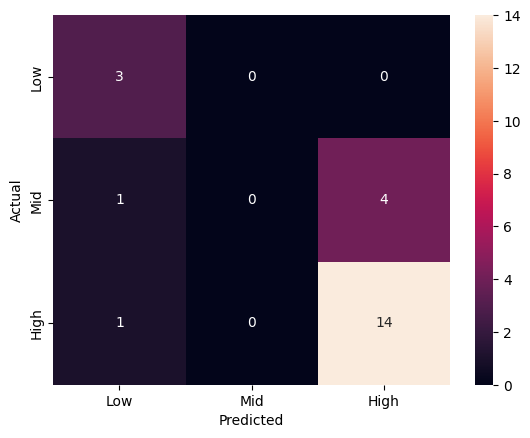

In [5]:
# Predict on your validation set
model.eval()
y_true, y_pred = [], []
for batch in val_loader:
    ids = batch['input_ids'].to(device)
    mask = batch['attention_mask'].to(device)
    labels = batch['s_label'].cpu().numpy()
    out_s, _, _ = model(ids, mask)
    preds = torch.argmax(out_s, dim=1).cpu().numpy()
    y_true.extend(labels)
    y_pred.extend(preds)

cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
print(cm)
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Low","Mid","High"],
            yticklabels=["Low","Mid","High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [7]:
model.eval()
y_true_s, y_pred_s = [], []
y_true_e, y_pred_e = [], []
y_true_t, y_pred_t = [], []

with torch.no_grad():
    for batch in val_loader:
        ids = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        s_lbl = batch['s_label'].cpu().numpy()
        e_lbl = batch['e_label'].cpu().numpy()
        t_lbl = batch['t_label'].cpu().numpy()

        out_s, out_e, out_t = model(ids, mask)
        preds_s = torch.argmax(out_s, dim=1).cpu().numpy()
        preds_e = torch.argmax(out_e, dim=1).cpu().numpy()
        preds_t = torch.argmax(out_t, dim=1).cpu().numpy()

        y_true_s.extend(s_lbl); y_pred_s.extend(preds_s)
        y_true_e.extend(e_lbl); y_pred_e.extend(preds_e)
        y_true_t.extend(t_lbl); y_pred_t.extend(preds_t)

# Compute metrics
sent_acc = accuracy_score(y_true_s, y_pred_s)
emo_f1   = f1_score(y_true_e, y_pred_e, average='macro')
top_acc  = accuracy_score(y_true_t, y_pred_t)

print(f"Sentiment Accuracy: {sent_acc:.3f}")
print(f"Emotion Macro-F1:   {emo_f1:.3f}")
print(f"Topic Accuracy:     {top_acc:.3f}")

# Optional: detailed report
print("\nSentiment classification report:\n", classification_report(y_true_s, y_pred_s))


Sentiment Accuracy: 0.739
Emotion Macro-F1:   0.256
Topic Accuracy:     0.565

Sentiment classification report:
               precision    recall  f1-score   support

           0       0.60      1.00      0.75         3
           1       0.00      0.00      0.00         5
           2       0.78      0.93      0.85        15

    accuracy                           0.74        23
   macro avg       0.46      0.64      0.53        23
weighted avg       0.59      0.74      0.65        23



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
